# Wind Climate Estimation from Short Measurement Campaigns

## Background

In wind energy and atmospheric science, we often face the following problem:

A reference station has measured wind speed continuously for many years, but a new site has only been monitored for a short period. The short record may not capture the full range of weather conditions and may therefore not represent the long-term climate.

To overcome this limitation, we can use the relationship between the short-term measurements and a nearby long-term reference station to estimate the long-term wind climate at the target location.

This exercise introduces two commonly used approaches:

1. **Linear Transfer Function**
2. **Quantile Mapping**

We will investigate how well these approaches reproduce:

- Mean wind speed
- Wind speed distributions
- Weibull parameters
- Wind power density

---

## Learning Objectives

After completing this exercise, you should be able to:

- Explain why short measurement campaigns can be misleading.
- Fit Weibull distributions to wind speed data.
- Construct a simple transfer function between two sites.
- Apply empirical quantile mapping.
- Evaluate the strengths and limitations of each method.
- Understand why errors in high wind speeds are important for wind energy applications.

---

## Scientific Question

Suppose that a target site has only been monitored for six months.

Can we use a nearby long-term reference station to reconstruct the long-term wind climate at the target site?
`

In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

from scipy.stats import weibull_min
from scipy.interpolate import interp1d

plt.rcParams["figure.figsize"] = (10,5)
plt.rcParams["axes.grid"] = True

# Load Data

We assume that:

- `reference_station.csv` contains a long wind speed record.
- `target_station.csv` contains the target station record.

Both files contain:

| Column | Description |
|----------|----------|
| time | Timestamp |
| ws | Wind speed (m/s) |

The target station record will later be artificially shortened to simulate a measurement campaign.

In [25]:
# Observations Adventdalen
ref_file = "/Users/irms/Library/CloudStorage/OneDrive-UniversityofBergen/UniB/UNIS/teaching/excersises/weibull/Adventdalen_Hour.dat"

ref = pd.read_csv(
    ref_file,
    skiprows=[0, 2, 3],  # skip metadata, units, and type rows
    parse_dates=["TIMESTAMP"]
)

target_file = '/Users/irms/Library/CloudStorage/OneDrive-UniversityofBergen/UniB/UNIS/teaching/excersises/weibull/Jansonhaugen_Res_data.dat'
# with open(target_file, "r", errors="ignore") as f:
#     for i in range(20):
#         print(f.readline().rstrip())

target = pd.read_csv(
    target_file,
    skiprows=[0, 2, 3],
    parse_dates=["TIMESTAMP"],
    na_values=["NAN", "NaN", "nan"]
)
target
# print(ref.head())
print(target.head())

            TIMESTAMP  RECORD   ID  LT10cm_minutt_Max  LT10cm_minutt_Min  \
0 2011-04-06 10:00:00       0  655                0.0                0.0   
1 2011-04-06 11:00:00       1  655                0.0                0.0   
2 2011-04-06 12:00:00       2  655                0.0                0.0   
3 2011-04-06 13:00:00       3  655                0.0                0.0   
4 2011-04-06 14:00:00       4  655                0.0                0.0   

   LT10cm_minutt_Avg  LT1m_minutt_Max  LT1m_minutt_Min  LT1m_minutt_Avg  \
0                0.0            23.05             0.00            22.68   
1                0.0            23.09             0.00            22.80   
2                0.0            23.22            22.96            23.08   
3                0.0            23.20            23.05            23.10   
4                0.0            23.22            23.09            23.19   

   LT3m_minutt_Max  ...  LF_minutt_Avg   AT_mbar  VH_mps_Max  VH_10_minutt  \
0            2

# Explore the Data

Before performing any statistical analysis, it is always useful to visualise the observations.

## Questions

1. Which station appears windier?
2. Can you identify seasonal variations?
3. Are there periods with unusually strong wind events?
4. Is the target record shorter than the reference record?

Overlap: 2016-01-01 00:00:00 to 2024-02-29 00:00:00


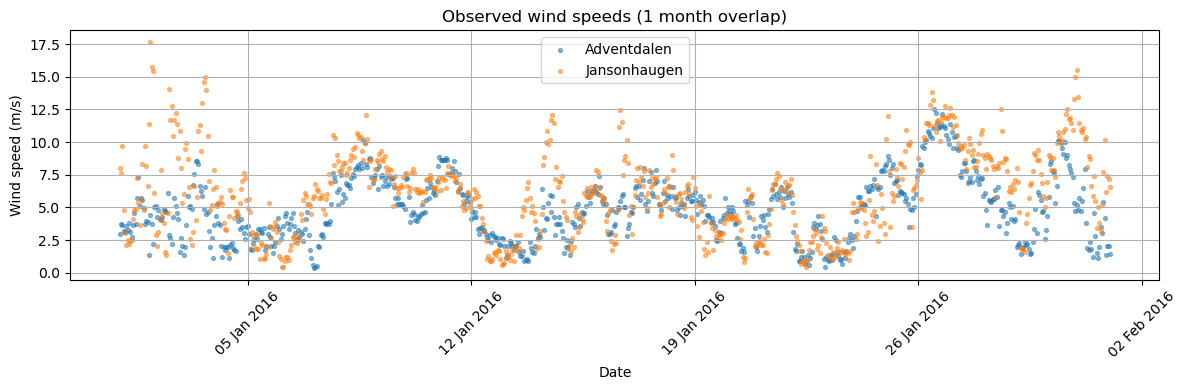

In [26]:
# Set datetime index
ref = ref.set_index("TIMESTAMP")
target = target.set_index("TIMESTAMP")

# Wind speeds
ref_ws = ref["VH1_mps_mid"]
target_ws = target["VH_mps_mid"]

# Find overlapping period
start = max(ref_ws.index.min(), target_ws.index.min())
end = min(ref_ws.index.max(), target_ws.index.max())

print("Overlap:", start, "to", end)

# Select first month of overlap
month_start = start
month_end = start + pd.DateOffset(months=1)

ref_month = ref_ws.loc[month_start:month_end]
target_month = target_ws.loc[month_start:month_end]

# Plot
fig, ax = plt.subplots(figsize=(12,4))

ax.scatter(
    ref_month.index,
    ref_month,
    s=8,
    alpha=0.5,
    label="Adventdalen"
)

ax.scatter(
    target_month.index,
    target_month,
    s=8,
    alpha=0.5,
    label="Jansonhaugen"
)

ax.set_xlabel("Date")
ax.set_ylabel("Wind speed (m/s)")
ax.set_title("Observed wind speeds (1 month overlap)")

# Nice date formatting
ax.xaxis.set_major_locator(mdates.WeekdayLocator(interval=1))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b %Y"))

plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

# Simulated Measurement Campaign

In reality, developers rarely have multiple years of observations from a new site.

To mimic a realistic situation, we now assume that only six months of measurements are available at the target location.

The full target record remains available only so that we can evaluate how successful our reconstruction methods are.

In [28]:
start = "2016-01-01"
end = "2016-02-01"

target_short = target.loc[month_start:month_end]
ref_overlap = ref.loc[month_start:month_end]


## Questions

1. Does the 1-month period seem representative of the full climate?
2. Could the selected period be unusually calm or unusually windy?
3. What climatic information might be missing from a 1-month campaign?

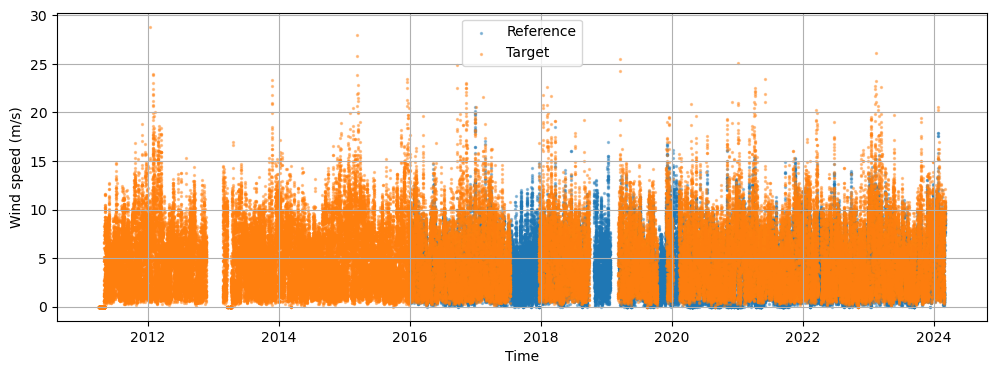

In [33]:
fig, ax = plt.subplots(figsize=(12,4))

ax.scatter(
    ref_ws.index,
    ref_ws,
    s=2,
    alpha=0.4,
    label="Reference"
)

ax.scatter(
    target_ws.index,
    target_ws,
    s=2,
    alpha=0.4,
    label="Target"
)

ax.set_xlabel("Time")
ax.set_ylabel("Wind speed (m/s)")
ax.legend()

plt.show()

# Mean Wind Speed

The average wind speed is often used as a simple summary of a site's climate.

However, two sites can have identical mean wind speeds while possessing very different wind speed distributions.

Let us first compare the mean values.

In [47]:
# ref_ws
ref_overlap['VH1_mps_mid']

TIMESTAMP
2016-01-01 00:00:00    2.979
2016-01-01 01:00:00    3.727
2016-01-01 02:00:00    3.637
2016-01-01 03:00:00    3.223
2016-01-01 04:00:00    3.100
                       ...  
2016-01-31 20:00:00    4.169
2016-01-31 21:00:00    1.330
2016-01-31 22:00:00    2.034
2016-01-31 23:00:00    2.040
2016-02-01 00:00:00    1.449
Name: VH1_mps_mid, Length: 745, dtype: float64

In [ ]:
print("Reference overlap mean:")
print(ref_overlap.mean())

print()

print("Target overlap mean:")
print(target_short.mean())

# print()

print("True target long-term mean:")
print(target.mean())


Reference overlap mean:
RECORD          5089.000000
ID               853.000000
LT1_gr_C_Max      -3.875940
LT1_gr_C_Min      -5.314760
LT1_gr_C_Avg      -4.604301
LT2_gr_C_Max      -3.287376
LT2_gr_C_Min      -4.671451
LT2_gr_C_Avg      -3.958686
LT3_gr_C_Max      -4.358910
LT3_gr_C_Min      -5.742086
LT3_gr_C_Avg      -5.057067
LF1_prst_Max      83.025356
LF1_prst_Avg      79.166617
LT4_gr_C_Max      -3.307550
LT4_gr_C_Min      -4.486145
LT4_gr_C_Avg      -3.881960
LF2_prst_Max      74.841302
LF2_prst_Avg      71.140805
AT_mbar         1008.890995
VH1_mps_Max        7.911906
VH1_10_min         4.821894
VH1_mps_mid        4.844989
VR1_gr_framh     133.997541
VH2_sek_Max        9.201299
VH2_10_min         5.956482
VH2_mps_mid        5.970144
VR2_gr_framh     132.575580
Batt_V_Min        13.757436
dtype: float64

Target overlap mean:
RECORD               39358.000000
ID                     655.000000
LT10cm_minutt_Max       -6.792623
LT10cm_minutt_Min       -7.324166
LT10cm_minutt_Avg  

## Discussion

Compare the short-term and long-term target means.

### Questions

1. Are the two values identical?
2. Why might they differ?
3. Would you trust a six-month average as a representation of climate?

# Weibull Distribution

Wind speed is commonly represented using a Weibull distribution:

\[
f(U)=
\frac{k}{A}
\left(\frac{U}{A}\right)^{k-1}
\exp\left[-\left(\frac{U}{A}\right)^k\right]
\]

where:

- \(U\) = wind speed
- \(A\) = scale parameter
- \(k\) = shape parameter

---

## Interpretation

### Scale parameter A

Controls the overall windiness of a site.

Higher values generally indicate stronger winds.

### Shape parameter k

Controls distribution shape.

Small values:

- broader distribution
- more variability

Large values:

- narrower distribution
- more consistent winds

In [ ]:
k_ref, loc_ref, A_ref = weibull_min.fit(
    ref.ws.dropna(),
    floc=0
)

k_short, loc_short, A_short = weibull_min.fit(
    target_short.ws.dropna(),
    floc=0
)

k_true, loc_true, A_true = weibull_min.fit(
    target.ws.dropna(),
    floc=0
)

print("Reference")
print("k =", round(k_ref,2))
print("A =", round(A_ref,2))

print()

print("Target short campaign")
print("k =", round(k_short,2))
print("A =", round(A_short,2))

print()

print("Target climatology")
print("k =", round(k_true,2))
print("A =", round(A_true,2))

In [ ]:
u = np.linspace(0,25,300)

plt.figure(figsize=(8,5))

plt.plot(
    u,
    weibull_min.pdf(u, k_ref, scale=A_ref),
    label="Reference"
)

plt.plot(
    u,
    weibull_min.pdf(u, k_short, scale=A_short),
    label="Short Campaign"
)

plt.plot(
    u,
    weibull_min.pdf(u, k_true, scale=A_true),
    label="True Target Climate"
)

plt.xlabel("Wind speed (m/s)")
plt.ylabel("Probability density")
plt.legend()

plt.show()

# Method 1: Linear Transfer Function

The simplest assumption is that wind speeds at the two sites differ by a constant factor:

\[
U_B = a U_A
\]

where:

- \(U_A\) is the reference station wind speed
- \(U_B\) is the target station wind speed
- \(a\) is a transfer coefficient

This method assumes that weak winds and strong winds scale in the same way.

In [ ]:
a = target_short.ws.mean() / ref_overlap.ws.mean()

print("Transfer coefficient =", round(a,3))

In [ ]:
target_linear = a * ref.ws

## Discussion

### Questions

1. Does linear scaling preserve the shape of the distribution?
2. Does it modify the relative frequency of strong winds?
3. Which Weibull parameter would you expect to change most strongly?

# Method 2: Quantile Mapping

Linear scaling treats all wind speeds equally.

Quantile mapping allows weak winds and strong winds to be adjusted differently.

The idea is simple:

- Find a percentile in the reference record.
- Find the corresponding percentile in the target record.
- Map one onto the other.

For example:

| Quantile | Reference | Target |
|----------|-----------|---------|
| 10% | 3 m/s | 2 m/s |
| 50% | 8 m/s | 6 m/s |
| 90% | 15 m/s | 13 m/s |

This allows the entire distribution shape to change.

In [ ]:
q = np.linspace(0,1,101)

ref_q = np.quantile(ref_overlap.ws, q)
tgt_q = np.quantile(target_short.ws, q)

qm = interp1d(
    ref_q,
    tgt_q,
    fill_value="extrapolate"
)

target_qm = qm(ref.ws)

In [ ]:
fig, ax = plt.subplots(figsize=(7,7))

ax.plot(ref_q, tgt_q)

ax.set_xlabel("Reference wind speed (m/s)")
ax.set_ylabel("Target wind speed (m/s)")
ax.set_title("Quantile Mapping Function")

plt.show()

# Compare Reconstructed Wind Climates

We now compare:

- True target climate
- Linear transfer estimate
- Quantile mapping estimate

The goal is to determine which method most successfully reproduces the long-term wind climate.

In [ ]:
fig, ax = plt.subplots(figsize=(8,5))

ax.hist(
    target.ws,
    bins=30,
    density=True,
    alpha=0.5,
    label="True"
)

ax.hist(
    target_linear,
    bins=30,
    density=True,
    alpha=0.5,
    label="Linear MCP"
)

ax.hist(
    target_qm,
    bins=30,
    density=True,
    alpha=0.5,
    label="Quantile Mapping"
)

ax.set_xlabel("Wind speed (m/s)")
ax.set_ylabel("Probability density")

ax.legend()

plt.show()

In [ ]:
k_lin, _, A_lin = weibull_min.fit(
    target_linear.dropna(),
    floc=0
)

k_qm, _, A_qm = weibull_min.fit(
    target_qm,
    floc=0
)

results = pd.DataFrame({
    "Method":["True","Linear MCP","Quantile Mapping"],
    "k":[k_true,k_lin,k_qm],
    "A":[A_true,A_lin,A_qm]
})

results.round(2)

# Wind Power Density

Wind energy depends on the cube of wind speed:

\[
P = \frac12 \rho U^3
\]

where

\[
\rho = 1.225\ kg\ m^{-3}
\]

This means that errors in strong winds have a much greater effect than errors in weak winds.

Consequently, two methods that produce similar mean wind speeds may still yield very different estimates of wind energy potential.

In [ ]:
rho = 1.225

P_true = (0.5*rho*target.ws**3).mean()
P_lin = (0.5*rho*target_linear**3).mean()
P_qm = (0.5*rho*target_qm**3).mean()

print("True         :", round(P_true,1))
print("Linear MCP   :", round(P_lin,1))
print("Quantile Map :", round(P_qm,1))

# Final Reflection

## Questions

### Understanding the Data

1. Why was the short measurement campaign not fully representative of the long-term climate?

### Transfer Function

2. What assumptions are made by the linear transfer method?
3. Under what conditions might those assumptions fail?

### Quantile Mapping

4. Why can quantile mapping alter both the Weibull scale parameter and shape parameter?
5. Why is quantile mapping often better at reproducing extremes?

### Wind Energy

6. Which method best reproduced mean wind speed?
7. Which method best reproduced wind power density?
8. Are these necessarily the same method?

### Broader Perspective

9. If only three months of observations were available, how would confidence in your estimate change?
10. What other information could help improve a long-term climate estimate?